# Clustering (agrupamiento)
---

* Método de **aprendizaje no supervisado** (se desconoce la clase)
* Método exploratorio
* Busca caracterizar conceptos desconocidos a partir de ejemplos disponibles
* Al no disponer de la clase utiliza una **medida de similitud** para determinar el parecido entre instancias

## Elementos básicos

* Identificar las características relevantes de cada tipo de elemento
* Indicar la manera en que se realizará la comparación **(DISTANCIA)**. Por ejemplo, que le mido a la papa para poder diferenciarla: el peso, el diámetro, el color, etc.
* El resultado de aplicar una técnica de clustering es una serie de agrupamientos o clusters formados al particionar las instancias

## Aplicaciones

* **Descubrimiento de grupos**: permite encontrar y describir grupos de instancias con características similares dentro de un conjunto de datos
* **Segmentación de clientes**: identifica clientes con perfiles y comportamientos similares para ofrecer servicios y productos adecuados y personalizados
* **Análisis académico**: identifica alumnos con rendimientos académicos similares, con el objetivo de diseñar estrategias para reducir la deserción escolar
* **Detección de anomalías**: permite detectar casos o patrones anómalos que se desvían significativamente del comportamiento esperado
* **Detección de fraudes**: facilita la identificación temprana de actividades o transacciones fraudulentas mediante el análisis de patrones
* **Análisis exploratorio de datos**: descubrir patrones ocultos, comprender la estructura de los datos y obtener conocimientos iniciales antes de aplicar otras técnicas analíticas más complejas

## Calidad del agrupamiento obtenido

* Un buen método de agrupamiento producirá grupos de alta calidad en los cuales el parecido entre los elementos:
    * que componen un mismo grupo es alto (intra-cluster)
    * de grupos distintos es bajo (inter-cluster)
* Minimizar la distancia entre los elementos de un mismo cluster (intra-cluster)
* Maximizar la distancia entre clusters (inter-cluster)
* **Los clusters son sensibles a la escala de las variables, tienen que estar estandarizadas**

## Proceso de Clustering

1. Seleccionar las características relevantes (Por ejemplo con ACP: Componentes principales)
2. Definir una representación adecuada (por ejemplo, estandarizar, pasar a valores Z entre [-3, 3])
3. Definir la medida de similitud a utilidad (medida de distancia). Depende del problema
4. Aplicar un algoritmo de agrupamiento
5. Validar los grupos obtenidos y de ser necesario volver a repetir el proceso. Utilizar distintas técnicas y después compararlas. O utilizar algunos indicadores
6. Analizar en el contexto de los datos y la interpretabilidad de los clusters, es decir, que significan esos clusters

## Tipos de algoritmos de Clustering

* **K-Means** (basado en centroides)
* **Jerárquico**
* **EM** (Expectation-Maximization, basado en distribuciones)
* **DBSCAN** (basado en densidad espacial)

### K-Means (basado en centroides)

* Es un método de agrupamiento particional (particionan los datos creando un número K de clusters)
* Una instancia pertenece a un único grupo
* Requiere conocer a priori el número K de clusters (grupos) a formar
* Divide los datos en k clusters
* Minimiza la suma de las distancias cuadradas entre los puntos y el centroide del cluster
* Itera entre: Asignar cada punto al cluster más cercano
* Recalcular los centroides, promediando esos datos
* **Ventajas**: rápido y sencillo
* **Limitaciones**: requiere definir k previamente, sensible a outliers y a la forma de los clusters (asume forma esférica)

1. Definir aleatoriamente k (cantidad de cluster) como centros iniciales. Por ej: 3
2. Para cada individuos se calcula la distancia al centro y se coloca en el grupo más cercano (mínima distancia euclídea al cuadrado)
3. Calcular los nuevos centros de los K clusters (cada centro se reubica promediando los valores de los atributos de los ejemplos que los conforman)
4. Repetir procedimiento hasta que los centros no cambien (estén constantes)

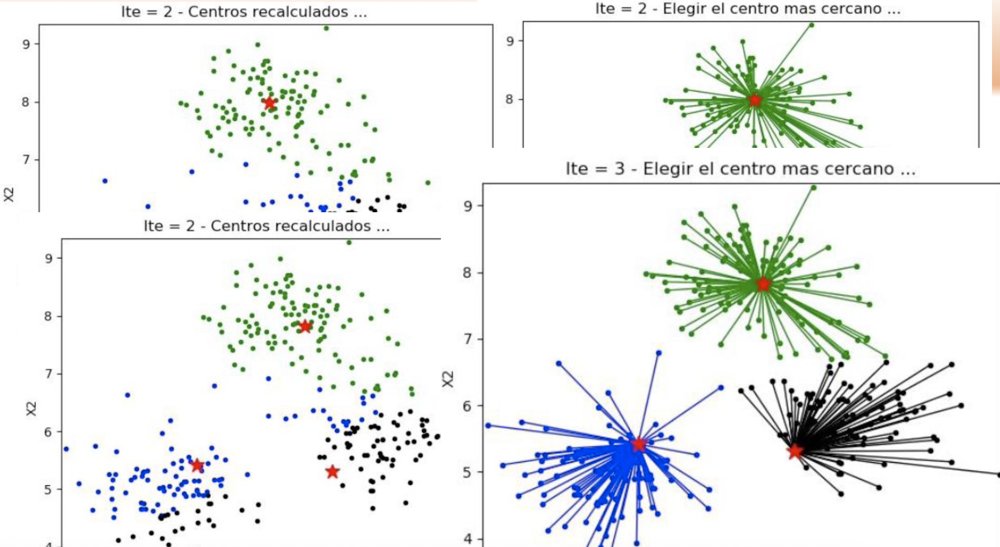

### Jerárquico

* No se necesita dar entrada la cantidad de clusters y se forman árboles
* construye una jerarquía de clusters que permiten ver las particiones de las instancias con distinta granularidad
* Una instancia pertenece a un único grupo
* Representa la estructura en un **dendrograma**
* Se fija distancia --> corte y cantidad de clusters
* Tipos:
    * **Aglomerativo**: empieza con cada punto como un cluster y los va fusionando (raíz abajo)
    * **Divisivo**: empieza con todos los puntos juntos y los va separando (raíz arriba)
* **Ventajas**: no necesita definir **k** al inicio, permite explorar diferentes niveles de agrupamiento
* **Limitaciones**: costoso computacionalmente para grandes datasets 

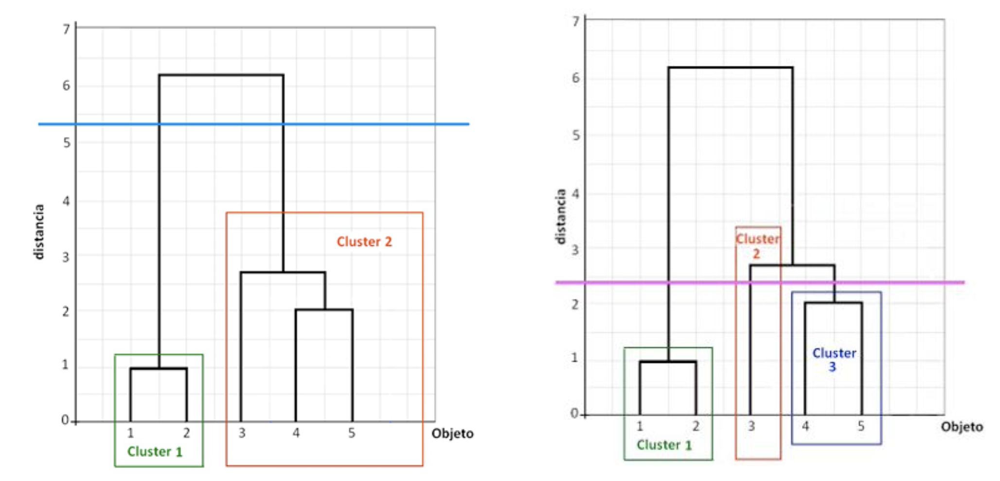

1. Tiene a los individuos separados y los va a agrupando
2. Toma la distancia entre 1 y 2
3. Hace promedio entre esas dos distancias, generando una nueva distancia que va a comparar con los individuos

* Cluster jerárquico se puede utilizar en la primera etapa para ver la estructura y definir la cantidad de clusters de kmedias (2da etapa)
* Se puede usar para casos o variables
* Cercanía en cuanto la distancia (no la dirección)

#### Construcción de dendograma

| Cluster | X1 | X2 | X3 |
| --      | -- | -- | -- |
| 1       | 1  | 1  | 2  |
| 2       | 1  | 2  | 5  |
| 3       | 2  | 1  | 4  |
| 4       | 5  | 5  | 2  |
| 5       | 5  | 5  | 6  |
| 6       | 7  | 5  | 4  |
| 7       | 8  | 8  | 5  |
| 8       | 7  | 6  | 5  |

In [1]:
import plotly.express as px
import numpy as np

X1 = np.array([1, 1, 2, 5, 5, 7, 8, 7])
X2 = np.array([1, 2, 1, 5, 5, 5, 8, 6])
X3 = np.array([2, 5, 4, 2, 6, 4, 5, 5])

fig = px.scatter_3d(x=X1, y=X2, z=X3)
fig.show()

In [2]:
# 1. Calculo de la matriz de distancias euclídeas
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist, squareform

X = np.column_stack((X1, X2, X3))

# Calcular la matriz de distancias euclídeas
matriz_distancias = squareform(pdist(X, metric='euclidean'))
matriz_distancias_df = pd.DataFrame(matriz_distancias, index=[f'{i+1}' for i in range(0, 8)], columns=[f'{i+1}' for i in range(0, 8)])
matriz_distancias_df.round(2)

,1,2,3,4,5,6,7,8
1,0.00,3.16,2.24,5.66,6.93,7.48,10.34,8.37
2,3.16,0.00,1.73,5.83,5.10,6.78,9.22,7.21
3,2.24,1.73,0.00,5.39,5.39,6.40,9.27,7.14
4,5.66,5.83,5.39,0.00,4.00,2.83,5.20,3.74
5,6.93,5.10,5.39,4.00,0.00,2.83,4.36,2.45
6,7.48,6.78,6.40,2.83,2.83,0.00,3.32,1.41
7,10.34,9.22,9.27,5.20,4.36,3.32,0.00,2.24
8,8.37,7.21,7.14,3.74,2.45,1.41,2.24,0.00


In [3]:
# 2. Distancia más pequeña: 1.41 
# 3. Agrupo punto 6 con 8
# 4. Calcular centroide
A = [(7+7)/2, (5+6)/2, (4+5)/2]
A

[7.0, 5.5, 4.5]

| Cluster | X1 | X2 | X3 |
| --      | -- | -- | -- |
| A       | 7  | 5.5| 4.5|
| 1       | 1  | 1  | 2  |
| 2       | 1  | 2  | 5  |
| 3       | 2  | 1  | 4  |
| 4       | 5  | 5  | 2  |
| 5       | 5  | 5  | 6  |
| 7       | 8  | 8  | 5  |

* Repito el procedimiento hasta tener un solo cluster

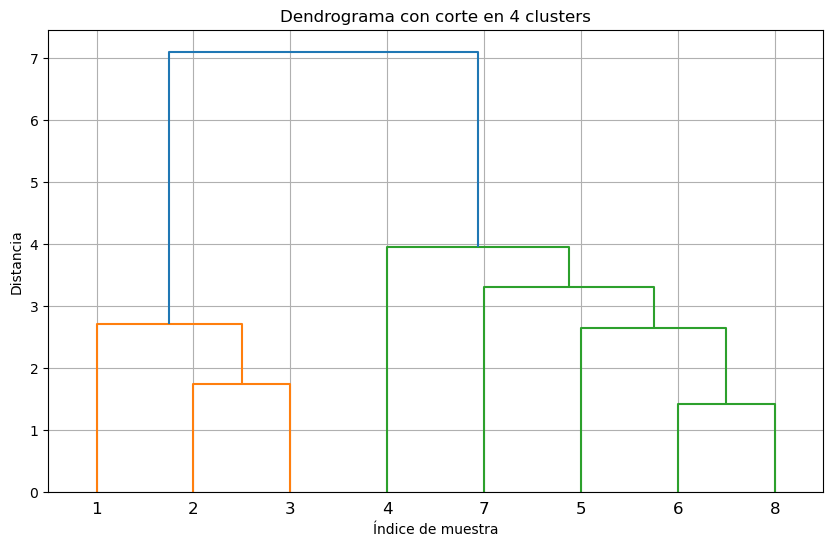

Asignación de clusters:
Punto 1: Cluster 1
Punto 2: Cluster 1
Punto 3: Cluster 1
Punto 4: Cluster 4
Punto 5: Cluster 2
Punto 6: Cluster 2
Punto 7: Cluster 3
Punto 8: Cluster 2


In [6]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import matplotlib.pyplot as plt

# Calcular el linkage (método de agrupamiento jerárquico)
Z = linkage(X, method='average')  # method: 'ward', 'single', 'complete', 'average'

# Cortar el árbol en k clusters
k = 4  # Puedes cambiar este número
clusters = fcluster(Z, k, criterion='maxclust')

# Dendrograma con colores
plt.figure(figsize=(10, 6))
dendrogram(Z, labels=np.arange(1, len(X)+1), color_threshold=None)
plt.title(f"Dendrograma con corte en {k} clusters")
plt.xlabel("Índice de muestra")
plt.ylabel("Distancia")
plt.grid(True)
plt.show()

# Mostrar a qué cluster pertenece cada punto
print("Asignación de clusters:")
for i, c in enumerate(clusters, start=1):
    print(f"Punto {i}: Cluster {c}")

* Si se corta el dendograma con una linea horizontal se determina el número de cluster (por ej. en 6 son 2 clusters, en 3 son 4 clusters)
* cuanto mas abajo se corte, hay mayor cantidad de clusters
* los individuos en un cluster tendrán ciertas caracteristicas distintas a otros individuos en otro cluster

### DBSCAN (basado en densidad)

* Agrupa puntos que están **densamente conectados**
* Define clusters según:
    * **ε (epsilon)**: radio de vecindad
    * **minPts**: número mínimo de puntos en la vecindad
* Identifica:
    * **Core points** (núcleo), **border points** y **ruido**
* **Ventajas**: detecta clusters de forma arbitraria y maneja ruido
* **Limitaciones**: sensible a la elección de parámetros ε y minPts

### EM (Expectation-Maximization)

* Basado en **modelos probabilísticos**, generalmente **mezcla de Gaussianas**
* Los clusters se definen como los objetos que pertenecen con mayor probabilidad a la misma distribución
* Itera entre:
    * **Expectation**: calcula la probabilidad de pertenencia de cada punto a cada cluster
    * **Maximization**: actualiza parámetros del modelo (medias, covarianzas)
* **Ventajas**: permite clusters elípticos y asignación probabilística (calcular la probabilidad de que un punto pertenezca a un determinado cluster)
* **Limitaciones**: puede converger a óptimos locales, requiere definir número de componentes

## Validación del agrupamiento

* Al no disponer de la clase utiliza una **medida de similitud** para determinar el parecido entre instancias
* Como el objetivo del clustering es agrupar objetos similares en el mismo cluster y objetos diferentes en distintos clusters, las métricas de validación (si el clustering es bueno o no) están basadas usualmente en los siguientes criterios:
    * **Cohesión**
    * **Separación**

### Cohesión (SSW - Sum of Square Within)

* **Proximidad interna**: se busca que los miembros de un mismo grupo se encuentren lo más cerca que sea posible unos de otros 

$$SSW = \Sigma^k_{i=1} \Sigma_{x \in C_i} dist^2(m_i,x)$$

* $k$: número de clusters
* $C_i$: conjunto de puntos que pertenecen al cluster $i$
* $m_i$: centroide (o media) del cluster $i$
* $x$: punto dentro del cluster $C_i$
* $dist^2(m_i, x)$: distancia al cuadrado entre el punto $x$ y el centroide $m_i$
* Interpretación:
    * Se calcula la **distancia al cuadrado entre cada punto y el centroide de su cluster**
    * **Se suman todas esas distancias para todos los clusters**
    * Cuanto **menor** sea el valor de SSW, **mayor es la cohesión del cluster**, porque los puntos están más cerca del centroide
    * **Indica** qué tan **compactos son los clusters**: valores bajos implican clusters más homogéneos

### Separación (SSB - Sum of Squares Between)

* **Distancia entre clusters**: los clusters deben estar ampliamente separados entre ellos
 
$$SSB = \Sigma^k_{j=1} n_j * dist^2(m_j, \bar x)$$

* $k$: número de clusters
* $n_j$: cantidad de elementos en el cluster $j$
* $m_j$: centroide (media) del cluster $j$
* $\bar x$: media global de todos los datos
* $dist^2(m_i, \bar x)$: distancia al cuadrado entre el centroide del cluster y la media global
* Interpretación:
    * SSB mide la separación entre clusters: cuanto más alejados estén los centroides respecto a la media global, mayor será el valor
    * SSB mide la variabilidad entre los centroides de los clusters
    * Un **SSB alto indica que los clusters están bien separados** (buena discriminación)

* Existen varios enfoques para medir esta distancia entre clusters:
    * distancia entre los miembros más cercanos,
    * distancia entre los miembros más distantes,
    * distancia entre los centroides.

### Indice Silhouette (se busca el más alto)

* Para cada punto i
    * $a(x_i)$: distancia promedio a los puntos del mismo cluster (cohesión)
    * $b(x_i)$: distancia promedio al cluster más cercano (separación)

$$S(x_i) = \dfrac{b(x_i) - a(x_i)}{max\{b(x_i), a(x_i)\}}$$

* Es una métrica [-1, 1] para evaluar la calidad de un clustering
* Calcula qué tan bien cada punto de datos se ajusta a su clúster en comparación con los clústeres vecinos. Un valor cercano a ...
* $S(x_i) > 0$: **bueno**, punto está bien asignado al cluster
* $S(x_i) = 0$:  **indiferente**, el punto está en el límite entre 2 clusters
* $S(x_i) < 0$: **mal agrupamiento**, el punto podría estar en un cluster incorrecto
* **SC: Índice de Silhoutte Medida Global**: para todo el agrupamiento es el promedio de la separación individual de $x_i$

$$SC = \dfrac{1}{N} \Sigma^N_{i=1} s(x_i)$$

* Será mejor cuanto mayor el índice
    * SC > 0.5, **ajusta bien**
    * 0.25 < SC <= 0.5, **ajusta mas o menos** 
    * SC < 0.25, **ajusta mal**

### Indice Davies-Bouldin (se busca el mas bajo)

* Compara a cada cluster con su vecino más cercano
* **dispersión de cada cluster**: distancia promedio entre los ejemplos que pertenecen al cluster y el centro del mismo

$$S_i = \dfrac{1}{|C_i|} \Sigma_{x \in C_i} dist(x, m_i)$$

* $|C_i|$ es la cantidad de elementos que pertenecen al cluster $C_i$
* $x$ es un elemento
* $m_i$ es el centroide de dicho cluster
* Cuanto más cerca del centro estén los puntos: menor $S_i$ => menor dispersión
* Cuanto más lejos del centro estén los puntos: mayor $S_i$ => mayor dispersión

* **distancia entre clusters**: $D_{ij}$ entre los centros de los clusters $C_i$ y $C_j$

$$D_{ij} = dist(m_i, m_j)$$ 

$$R_{ij} = \dfrac{S_i + S_j}{D_{ij}}$$

* $m_i$ y $m_j$ son los centroides de los clusters $C_i$ y $C_j$ respectivamente
* menor $D_{ij}$ => mayor $R_{ij}$ => menos compactos y mas alejados
* mayor $D_{ij}$ => menor $R_{ij}$ => más compactos y mas separados (es lo que se busca)
* Mientras más compactos sean los clusters $C_i$ y $C_j$ **menores** serán $S_i$ y $S_j$, y mientras más separados estén, **mayor** será $D_{ij}$
* Por lo tanto, cuanto más compactos sean los grupos y más separados se encuentren, **menor** será el valor de $R_{ij}$

* El índice Davies-Bouldin se define como 

$$DB = \dfrac{1}{k} \Sigma^k_{i=1} max_{i!=j}(R_{ij})$$

* $k$ es el número de clusters
* $max(R_{ij})$ con i!=j, es el "peor caso" para el cluster $C_i$
* Será mejor cuanto menor sea el valor del índice DB
* El valor del índice no está acotado. Puede tomar un valor arbitrario
* Interpretación:
    * DB bajo (≈ 0.3 - 0.7) => Clusters bien definidos
    * DB alto (> 1.5) => Clusters poco separados o muy dispersos

## Ejemplo

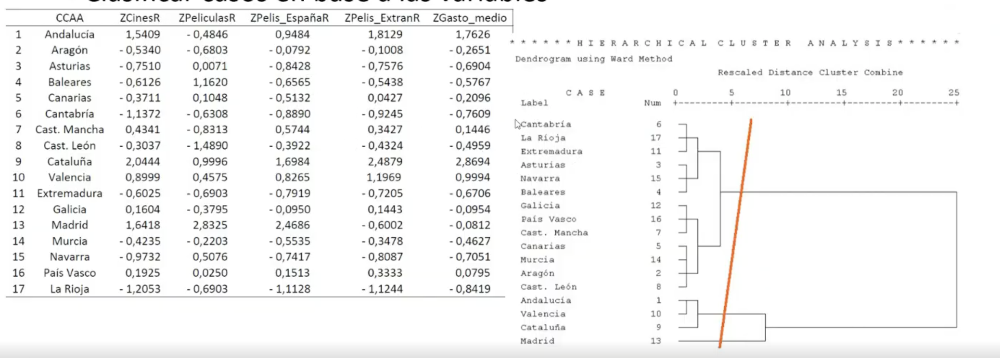

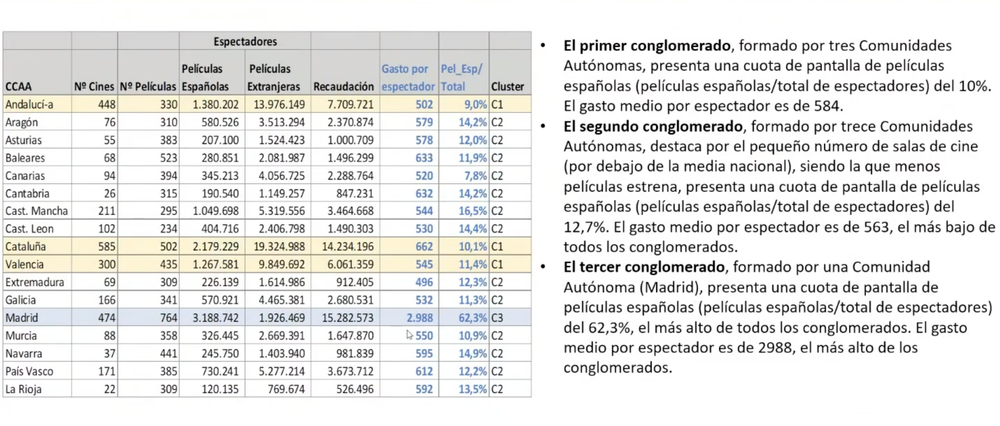

### Resumen del cluster

* Número de cluster
* Media
* Mín
* Máx

## Medidas de distancia

* **Distancia Euclidiana** (la más utilizada): distancia clásica, como la longitud de la recta que uno dos puntos en el espacio euclídeo

$$d(x,y) = \sqrt {\Sigma^n_{i=1} (x_i - y_i)^2}$$

* **Distancia Manhattan**: distancia por cuadras (city-block). Recorrer un camino no en diagonal sino zigzagueando

$$d(x,y) = \Sigma^n_{i=1} |x_i - y_i|$$

* **Ejemplo**: Se tienen dos puntos en el plano: A(2,3) y B(5,1)
* $d_{Manhattan} = 5$
* $d_{euclidea} = 3.61$

## Correlación medida de similaridad

* Correlación como distancia de individuos entre [-1, 1]
* Mide similaridad

$$r = \dfrac{\Sigma (x_i - \bar x)(y_i - \bar y)}{\sqrt{\Sigma (x_i - \bar x)^2  \Sigma (y_i - \bar y)^2}}$$

## Distancia en datos nominales (si/no)

|        | Y = 0 | Y = 1 |
| --     | --    | --    |
| X = 0  | a     | b     |
| X = 1  | c     | d     |

* Coeficientes:
    * Coincidencias simples: $\dfrac{a+d}{a+b+c+d}$
    * Jaccard: $\dfrac{d}{b+c+d}$
    * Phi
    * Anderberg
    * Dice: $\dfrac{2d}{b + c + 2d}$

* Ejemplo usando fórmula coincidencias simples (diagonal principal / total)

| ID  | P1 | P2 | P3 | P4 | P5 |
| --  | -- | -- | -- | -- | -- |
| ID1 | Si | Si | No | No | Si |
| ID2 | Si | No | No | No | No |
| ID3 | Si | No | Si | Si | Si |

| ID1-2 | Si | No |
| --    | -- | -- |
| Si    | 1  | 0  |
| No    | 2  | 2  |

$$d=(1+2)/5 = 0.6$$ 

| ID1-1 | Si | No |
| --    | -- | -- |
| Si    | 3  | 0  |
| No    | 0  | 2  |

$$d=(3+2)/5 = 1$$ 

| ID1-3 | Si | No |
| --    | -- | -- |
| Si    | 2  | 2  |
| No    | 1  | 0  |

$$d=(2+0)/5 = 0.4$$ 

* Tabla con similitud de individuos

| ID  | ID1 | ID2 | ID3 |
| --  | --  | --  | --  |
| ID1 | 1   | 0.6 | 0.4 |
| ID2 | 0.6 | 1   |     |
| ID3 | 0.4 |     | 1   |

## Criterios para selección de número k de cluster

* La mayoría de las medidas de evaluación se basan en criterios que utilizan el número de ejemplos que el modelo contempla. Existen otras aproximaciones que evalúan modelos basándose en criterios tales como:
* **Interés**: el interés de un modelo intenta medir la capacidad de ese modelo de suscitar la atención del usuario del modelo
* **Novedad**: criterio relacionado con la capacidad de un modelo de sorprender al usuario con respecto al conocimiento previo que tenía sobre determinado problema. Criterio muy afín al interés
* **Comprensibilidad o Inteligibilidad**: la comprensibilidad de un modelo es en algunas ocasiones un factor muy importante
* **Simplicidad**: establecer el tamaño o complejidad del modelo. Está muy relacionado con el criterio de comprensibilidad
* **Aplicabilidad**: capacidad de ser utilizado con éxito en el contexto real donde va a ser aplicado
* Algunos de estos criterios están muy relacionados, por ejemplo, el interés y la novedad, el interés y la aplicabilidad, así como la comprensibilidad y la simplicidad
* Se busca que haya la menor cantidad de cluster posibles y que sean explicables las diferencias entre los grupos